# SkinCare Review Project – Exploratory Data Analysis (EDA)

**Project:** Review-Informed Skincare Product Discovery Using NLP and Data Analytics  
**Product:** The Derma Co 2% Sali-Cinamide Anti-Acne Face Wash

This notebook explores the preprocessed review dataset before sentiment modelling. It covers:
- Dataset structure and quality
- Rating distribution and summary statistics
- Review length patterns
- Review trends over time
- Verified-buyer distribution
- Review examples by rating
- Frequent words in cleaned reviews

**Input:** `TheDermaCo_Preprocessed_Reviews.csv`  
**Output:** EDA charts and summary tables (the source CSV is not modified).

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 150)
pd.set_option("display.max_columns", None)

## 2. Load the preprocessed dataset

Place `TheDermaCo_Preprocessed_Reviews.csv` in the same folder as this notebook.

In [2]:
INPUT_FILE = "TheDermaCo_Preprocessed_Reviews.csv"

df = pd.read_csv(INPUT_FILE)

print("Dataset shape:", df.shape)
print("Number of reviews:", len(df))
display(df.head())

Dataset shape: (162, 16)
Number of reviews: 162


,review_id,product_name,reviewer_name,rating,review_title,review_text,review_date,verified_buyer,helpful_votes,not_helpful_votes,product_url,combined_review,cleaned_review,is_product_name_only,review_length,character_count
0,e18ed183-d1fb-4f47-9e5c-84e2edb3010b,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),Tejas,5,Good,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),2026-09-13T05:10:00Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-with-2-salicylic-acid-2-niacinamide-150-ml-pack-of-2,Good 2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),good 2 sali cinamide anti acne face wash with 2 salicylic acid 2 niacinamide 150ml pack of 2,True,18,100
1,8d555059-7343-4220-a9aa-98144cd5156e,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),Kabibunisa,5,NaN,It is the super product for pimple remove,2026-08-14T02:29:15Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-with-2-salicylic-acid-2-niacinamide-150-ml-pack-of-2,It is the super product for pimple remove,it is the super product for pimple remove,False,8,41
2,a4d3af1b-81db-4efd-8667-1dc49e7deb3d,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),Sayma,5,Fight acne and oil control,"Yeh derma ka best facewash h isme niacinamide, salicylic acid h jo acne prone skin ke liye better h\nMuje derma ke sabhi products bhot hi pasand a...",2026-08-07T05:40:16Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-with-2-salicylic-acid-2-niacinamide-150-ml-pack-of-2,"Fight acne and oil control Yeh derma ka best facewash h isme niacinamide, salicylic acid h jo acne prone skin ke liye better h\nMuje derma ke sabh...",fight acne and oil control yeh derma ka best facewash h isme niacinamide salicylic acid h jo acne prone skin ke liye better h muje derma ke sabhi...,False,80,418
3,1c619545-cd14-477e-9c28-5abe6fc21b9b,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),Athar .,5,NaN,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),2026-08-02T07:12:10Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-with-2-salicylic-acid-2-niacinamide-150-ml-pack-of-2,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),2 sali cinamide anti acne face wash with 2 salicylic acid 2 niacinamide 150ml pack of 2,True,17,95
4,58d6f486-ec74-469e-b82b-ad8c4190fdfc,2% Sali-Cinamide Anti-Acne Face Wash with 2% Salicylic Acid & 2% Niacinamide - 150ml (Pack of 2),Lucky,5,NaN,Nice,2026-02-22T05:52:29Z,False,0,0,/products/2-sali-cinamide-anti-acne-face-wash-with-2-salicylic-acid-2-niacinamide-150-ml-pack-of-2,Nice,nice,False,1,4


## 3. Inspect columns, data types and data quality

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("data_type"))

print("\nMissing values:")
display(df.isna().sum().to_frame("missing_values"))

print("\nDuplicate review IDs:", df["review_id"].duplicated().sum())

Column names:
['review_id', 'product_name', 'reviewer_name', 'rating', 'review_title', 'review_text', 'review_date', 'verified_buyer', 'helpful_votes', 'not_helpful_votes', 'product_url', 'combined_review', 'cleaned_review', 'is_product_name_only', 'review_length', 'character_count']

Data types:


,data_type
review_id,str
product_name,str
reviewer_name,str
rating,int64
review_title,str
review_text,str
review_date,str
verified_buyer,bool
helpful_votes,int64
not_helpful_votes,int64



Missing values:


,missing_values
review_id,0
product_name,0
reviewer_name,0
rating,0
review_title,9
review_text,0
review_date,0
verified_buyer,0
helpful_votes,0
not_helpful_votes,0



Duplicate review IDs: 0


## 4. Rating analysis

In [4]:
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

rating_counts = (
    df["rating"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
    .sort_index()
)

rating_summary = pd.DataFrame({
    "review_count": rating_counts,
    "percentage": (rating_counts / rating_counts.sum() * 100).round(2)
})

display(rating_summary)

print("Average rating:", round(df["rating"].mean(), 2))
print("Median rating:", df["rating"].median())

,review_count,percentage
rating,,
1,4,2.47
2,0,0.00
3,0,0.00
4,26,16.05
5,132,81.48


Average rating: 4.74
Median rating: 5.0


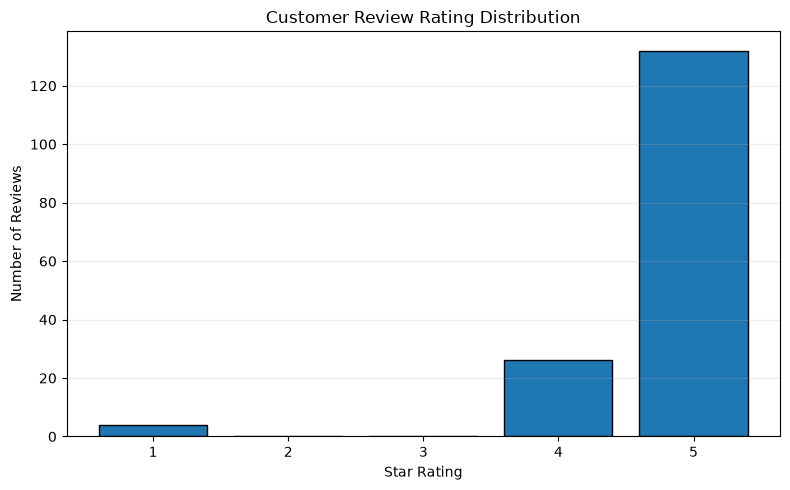

In [5]:
plt.figure(figsize=(8, 5))
plt.bar(rating_counts.index.astype(str), rating_counts.values, edgecolor="black")
plt.title("Customer Review Rating Distribution")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.xticks([0, 1, 2, 3, 4], ["1", "2", "3", "4", "5"])
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Review length analysis

In [6]:
if "review_length" not in df.columns:
    text_col = "cleaned_review" if "cleaned_review" in df.columns else "combined_review"
    df["review_length"] = df[text_col].fillna("").astype(str).apply(
        lambda x: len(x.split())
    )

display(df["review_length"].describe().to_frame("word_count"))

print("Shortest review (words):", df["review_length"].min())
print("Longest review (words):", df["review_length"].max())
print("Average review length:", round(df["review_length"].mean(), 2))

,word_count
count,162.000000
mean,31.104938
std,19.131973
min,1.000000
25%,18.250000
50%,28.000000
75%,37.750000
max,102.000000


Shortest review (words): 1
Longest review (words): 102
Average review length: 31.1


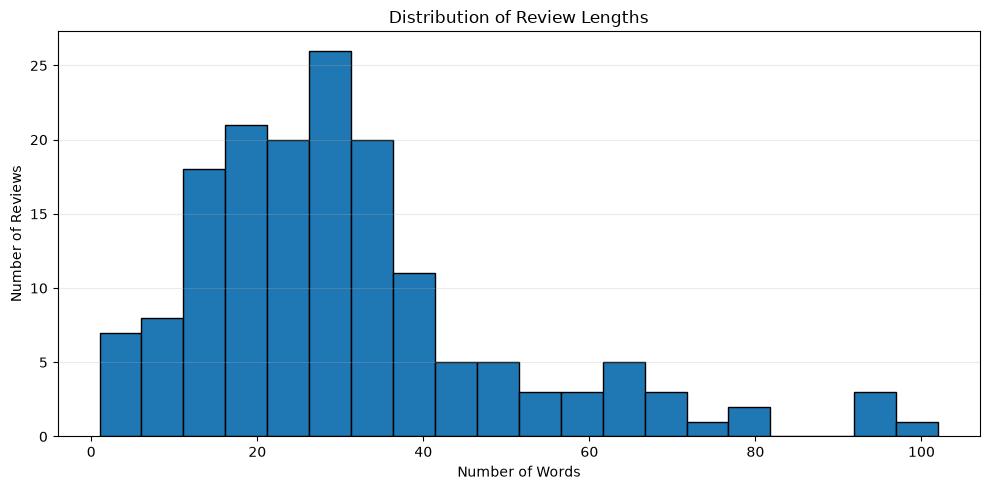

In [7]:
plt.figure(figsize=(10, 5))
plt.hist(df["review_length"].dropna(), bins=20, edgecolor="black")
plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

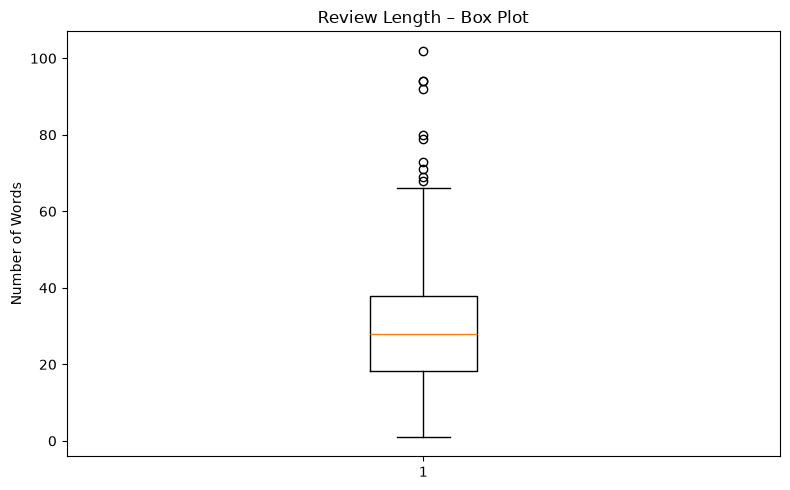

In [8]:
plt.figure(figsize=(8, 5))
plt.boxplot(df["review_length"].dropna(), orientation="vertical")
plt.title("Review Length – Box Plot")
plt.ylabel("Number of Words")
plt.tight_layout()
plt.show()

## 6. Review date trend

The date column is parsed into a datetime value. Invalid or missing dates are excluded from the time-series chart, not deleted from the dataset.

In [9]:
df["review_date_parsed"] = pd.to_datetime(
    df["review_date"], errors="coerce", utc=True
)

print("Valid review dates:", df["review_date_parsed"].notna().sum())
print("Invalid/missing review dates:", df["review_date_parsed"].isna().sum())

monthly_reviews = (
    df.dropna(subset=["review_date_parsed"])
      .set_index("review_date_parsed")
      .resample("MS")
      .size()
)

display(monthly_reviews.rename("review_count").to_frame())

Valid review dates: 162
Invalid/missing review dates: 0


,review_count
review_date_parsed,
2024-03-01 00:00:00+00:00,5
2024-04-01 00:00:00+00:00,5
2024-05-01 00:00:00+00:00,0
2024-06-01 00:00:00+00:00,0
2024-07-01 00:00:00+00:00,4
2024-08-01 00:00:00+00:00,1
2024-09-01 00:00:00+00:00,9
2024-10-01 00:00:00+00:00,13
2024-11-01 00:00:00+00:00,7


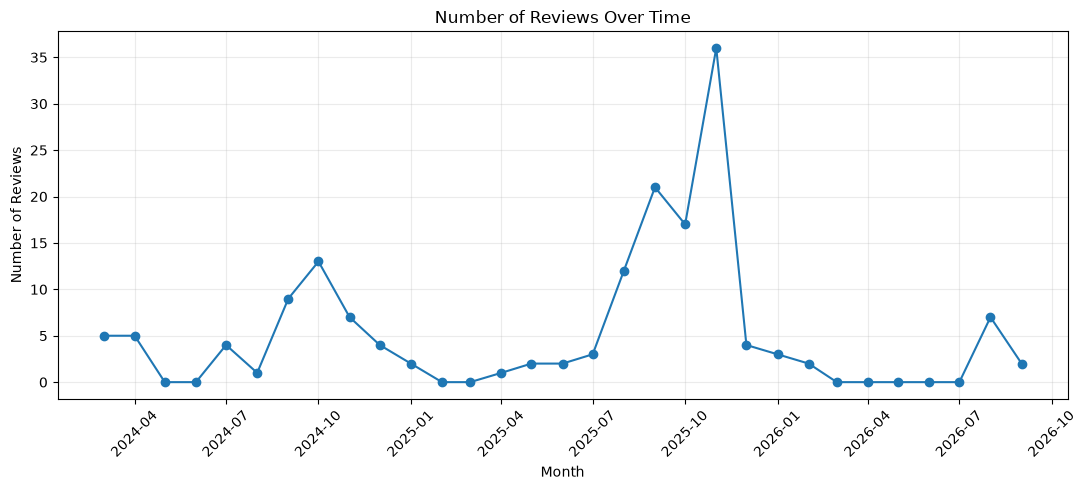

In [10]:
if not monthly_reviews.empty:
    plt.figure(figsize=(11, 5))
    plt.plot(monthly_reviews.index, monthly_reviews.values, marker="o")
    plt.title("Number of Reviews Over Time")
    plt.xlabel("Month")
    plt.ylabel("Number of Reviews")
    plt.xticks(rotation=45)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("No valid review dates available for the time-series chart.")

## 7. Verified-buyer distribution

This field reflects the value captured from the review widget. It should be interpreted as the site's displayed flag, not independent verification.

,review_count
verified_buyer,
False,162


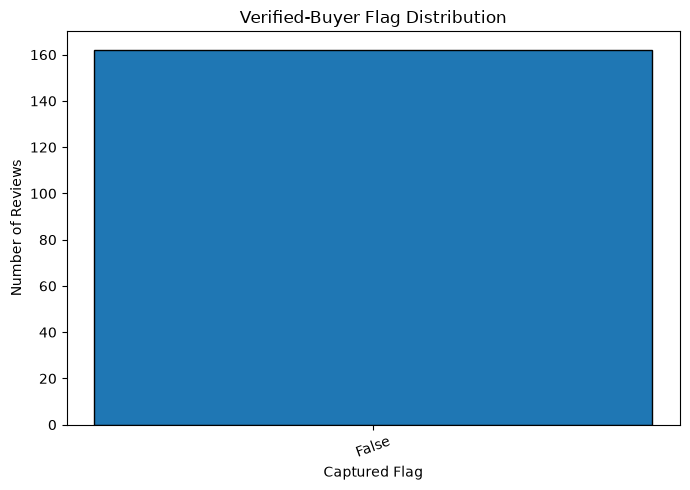

In [11]:
if "verified_buyer" in df.columns:
    verified_counts = (
        df["verified_buyer"]
        .fillna("Unknown")
        .astype(str)
        .value_counts()
    )
    display(verified_counts.rename("review_count").to_frame())

    plt.figure(figsize=(7, 5))
    plt.bar(verified_counts.index, verified_counts.values, edgecolor="black")
    plt.title("Verified-Buyer Flag Distribution")
    plt.xlabel("Captured Flag")
    plt.ylabel("Number of Reviews")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

## 8. Compare review length by rating

In [12]:
length_by_rating = (
    df.dropna(subset=["rating"])
      .groupby("rating")["review_length"]
      .agg(["count", "mean", "median"])
      .round(2)
)

display(length_by_rating)

,count,mean,median
rating,,,
1,4,24.75,25.5
4,26,32.04,28.0
5,132,31.11,28.5


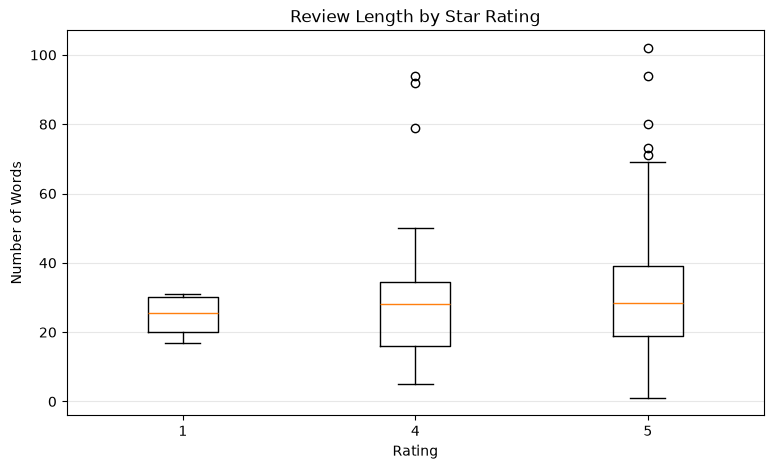

In [13]:
rating_groups = [
    df[df["rating"] == rating]["review_length"].dropna()
    for rating in sorted(df["rating"].dropna().unique())
]

labels = sorted(df["rating"].dropna().unique())

nonempty = [
    (values, label)
    for values, label in zip(rating_groups, labels)
    if len(values) > 0
]

if nonempty:
    plt.figure(figsize=(9, 5))

    plt.boxplot(
        [x[0] for x in nonempty],
        tick_labels=[x[1] for x in nonempty],
        orientation="vertical"
    )

    plt.title("Review Length by Star Rating")
    plt.xlabel("Rating")
    plt.ylabel("Number of Words")
    plt.grid(axis="y", alpha=0.3)
    plt.show()
else:
    print("No review length data available for the rating groups.")

## 9. Review examples by rating

Inspect actual customer feedback to understand what ratings represent. These are examples from the dataset, not automatically classified sentiments.

In [14]:
text_column = "cleaned_review" if "cleaned_review" in df.columns else "review_text"

for rating in [1, 2, 3, 4, 5]:
    subset = df.loc[df["rating"] == rating, ["reviewer_name", text_column]]
    print(f"\\n--- {rating}-star reviews ({len(subset)}) ---")
    display(subset.head(5))

\n--- 1-star reviews (4) ---


,reviewer_name,cleaned_review
158,Himang,missing product i ordered 4 item but got only 2 i was a big scam for me because i ordered 2 item with pack but i got only item delivered
159,Anjanay singh,don t buy this i ordered this product and they delivered 1 of 150 ml and 1 pack of 80 ml
160,kishan,ek no ka farji app h mere sath frod huaa sunscreen ki jgh moisturizer bhej diya sasta wala upr se inka costumer support or nhi h 1000 ka frod kr ...
161,vishaldoi gurjar,2 sali cinamide anti acne face wash with 2 salicylic acid 2 niacinamide 150ml pack of 2


\n--- 2-star reviews (0) ---


,reviewer_name,cleaned_review


\n--- 3-star reviews (0) ---


,reviewer_name,cleaned_review


\n--- 4-star reviews (26) ---


,reviewer_name,cleaned_review
132,Customer,i really like this face wash it cleans my skin very well without making it feel too dry the niacinamide works really well for my skin and i ve ...
133,Namita,best face wash ever i used this face wash clear my acne in 2 week very useful and showing very fast result
134,Badsha khan,really good really good product
135,Swati Gupta,i am using d i am using derma co 2 sali cinamide anti acne face wash is a gentle yet effective cleanser that tackles acne and reduces inflamma...
136,Bhavana Chaudhary,the derma co the derma co 2 salicylic acid and 2 niacinamide face wash foams beautifully and cleanses deeply the salicylic acid exfoliation seb...


\n--- 5-star reviews (132) ---


,reviewer_name,cleaned_review
0,Tejas,good 2 sali cinamide anti acne face wash with 2 salicylic acid 2 niacinamide 150ml pack of 2
1,Kabibunisa,it is the super product for pimple remove
2,Sayma,fight acne and oil control yeh derma ka best facewash h isme niacinamide salicylic acid h jo acne prone skin ke liye better h muje derma ke sabhi...
3,Athar .,2 sali cinamide anti acne face wash with 2 salicylic acid 2 niacinamide 150ml pack of 2
4,Lucky,nice


## 10. Most frequent words

This uses the already cleaned text. The list is a simple frequency count and has not yet removed stopwords, product terms or repeated generic words. It is exploratory, not a topic model.

In [15]:
from collections import Counter

if "cleaned_review" in df.columns:
    text_data = df["cleaned_review"].fillna("").astype(str)
else:
    text_data = df["review_text"].fillna("").astype(str)

tokens = " ".join(text_data).split()
word_freq = Counter(tokens)

top_words = pd.DataFrame(
    word_freq.most_common(25),
    columns=["word", "frequency"]
)

display(top_words)

,word,frequency
0,and,191
1,acne,169
2,the,160
3,i,150
4,my,143
5,skin,136
6,it,129
7,face,124
8,this,120
9,wash,110


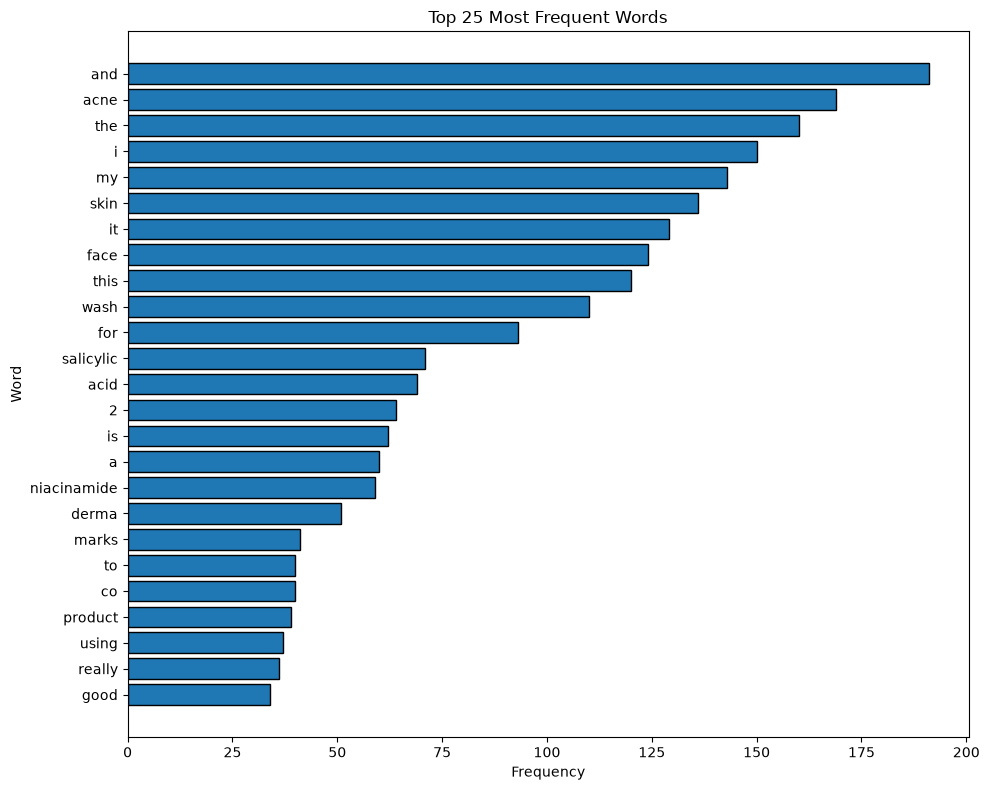

In [16]:
if not top_words.empty:
    plot_data = top_words.sort_values("frequency")
    plt.figure(figsize=(10, 8))
    plt.barh(plot_data["word"], plot_data["frequency"], edgecolor="black")
    plt.title("Top 25 Most Frequent Words")
    plt.xlabel("Frequency")
    plt.ylabel("Word")
    plt.tight_layout()
    plt.show()
else:
    print("No tokens available to plot.")

## 11. Correlation check

A rating/length correlation can be calculated as a descriptive check. It does not establish causation, and the rating distribution is heavily concentrated at 5 stars.

In [17]:
correlation_data = df[["rating", "review_length"]].dropna()

if len(correlation_data) >= 2 and correlation_data["rating"].nunique() > 1:
    correlation = correlation_data["rating"].corr(correlation_data["review_length"])
    print("Pearson correlation (rating vs review length):", round(correlation, 3))
else:
    print("Not enough rating variation to calculate a meaningful correlation.")

Pearson correlation (rating vs review length): 0.036


## 12. EDA summary

In [18]:
print("========== EDA SUMMARY ==========")
print("Total reviews:", len(df))
print("Unique review IDs:", df["review_id"].nunique())
print("Average rating:", round(df["rating"].mean(), 2))
print("Median review length:", df["review_length"].median())
print("Average review length:", round(df["review_length"].mean(), 2))
print("Most common rating:", df["rating"].mode().iloc[0] if df["rating"].notna().any() else "N/A")
print("Product-name-only reviews:", int(df["is_product_name_only"].sum()) if "is_product_name_only" in df.columns else "Not flagged")

========== EDA SUMMARY ==========
Total reviews: 162
Unique review IDs: 162
Average rating: 4.74
Median review length: 28.0
Average review length: 31.1
Most common rating: 5
Product-name-only reviews: 3


## 13. Save EDA-ready dataset

The notebook adds `review_date_parsed` for analysis and saves a separate EDA copy. It does not overwrite the original scraped or preprocessed files.

In [19]:
OUTPUT_FILE = "TheDermaCo_EDA_Analysis.csv"
df.to_csv(OUTPUT_FILE, index=False, encoding="utf-8-sig")
print("EDA dataset saved:", OUTPUT_FILE)

EDA dataset saved: TheDermaCo_EDA_Analysis.csv
